# 02　接收数据解调出原始比特

从 `qpsk_03_capture.npz` 里取 03 抓到的原始缓冲，一步步还原出比特。
**每个单元都对应接收机的一个真实环节**，可以单独停下来看波形/数值。

```
原始 4.19 M 字
  → ① 突发定位（块能量）           find_active
  → ② 去直流（静默块估计）          estimate_dc
  → ③ 匹配滤波 + 频谱方向自判        convolve / conj
  → ④ 粗定时 + 粗频偏                acquire
  → ⑤ 逐帧精同步（逐样点 + 带限 FFT） frame_sync
  → ⑥ 分数定时 + 前导相位拟合
  → ⑦ 二阶判决引导锁相环            pll_track
  → ⑧ 判决 + Gray 逆映射            demod_qpsk
```

其中 ⑤~⑧ 在 `frame_sync()` 里一次完成，本 notebook 会把它拆开重跑一遍，好让每一步的中间量都能看见。

> 依赖：先跑 `03_qpsk_tx_rx.ipynb` 生成 `qpsk_03_capture.npz`。

## 0　运行环境与前置文件

本 notebook 只处理 `.npz`，**不碰 PL / DMA**，所以断电重启后不需要初始化硬件；
但要先有上一步留下的数据文件。缺文件时按下面的提示补跑。

| 文件 | 产生者 | 内容 |
|---|---|---|
| `qpsk_03_capture.npz` | `03_qpsk_tx_rx`（自己会拉时钟和位流） | 原始 4.19 M 字 + 真值比特 |
| `qpsk_04_demod.npz` | `04_qpsk_demod` | 解出的比特 + 每帧定时/频偏 |


In [26]:
import sys, os

# 本文件夹（notebook、.py、.npz 都在这里）；旧位置只作向下兼容
QPSK_DIR = "/home/xilinx/jupyter_notebooks/qpsk"
LEGACY_DIR = "/home/xilinx/qpsk"
for _p in (QPSK_DIR, LEGACY_DIR):
    if _p not in sys.path:
        sys.path.insert(0, _p)


def npz(name):
    """本文件夹优先，旧位置兜底。"""
    p = os.path.join(QPSK_DIR, name)
    if not os.path.exists(p) and os.path.exists(os.path.join(LEGACY_DIR, name)):
        return os.path.join(LEGACY_DIR, name)
    return p


for _n, _who in (("qpsk_03_capture.npz", "03_qpsk_tx_rx.ipynb"),):
    _p = npz(_n)
    print("%-22s %s" % (_n, ("OK   " + _p) if os.path.exists(_p)
                        else "缺失 —— 先跑 %s" % _who))


qpsk_03_capture.npz    OK   /home/xilinx/qpsk/qpsk_03_capture.npz


In [27]:
import sys, os, time, json
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

%matplotlib inline

# 路径与 npz() 已在第 0 节定义

import qpsk_dsp as D

plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.grid": True, "grid.alpha": 0.3, "font.size": 9,
    "axes.titlesize": 10, "legend.fontsize": 8,
})

print("numpy    :", np.__version__)
print("qpsk_dsp :", D.__file__)
print("SPS      :", D.SPS, "  Rolloff:", D.ROLLOFF, "  SPAN:", D.SPAN)
print("前导     : %d 符号 ZC (root=%d)，帧间保护 %d 符号"
      % (D.N_PRE, D.ZC_ROOT, D.GUARD_SYM))

NPZ_TX = npz("qpsk_03_capture.npz")
NPZ_RX = npz("qpsk_04_demod.npz")

z = np.load(NPZ_TX, allow_pickle=False)
words   = z["words"]
n_real  = int(z["n_real"])
N_BITS  = int(z["n_bits"])
N_FRAMES = int(z["n_frames"])
SPS     = int(z["sps"])
LEAD    = int(z["lead"])
SPF_SMP = int(z["spf_smp"])
BB_LEN  = int(z["bb_len"])
FS_WORD = float(z["fs_word"])
tags    = [str(t) for t in z["tags"]]
truth   = [z["truth_%d" % i] for i in range(N_FRAMES)]

x_raw = D.from_words(words)
x = x_raw[:n_real] if n_real else x_raw

print("读入 %s (%.2f MB)" % (NPZ_TX, os.path.getsize(NPZ_TX) / 1e6))
print("原始字数 %d → 有效 %d，字率 %.3f MHz，SPS %d"
      % (len(x_raw), len(x), FS_WORD / 1e6, SPS))
print("帧数 %d，每帧 %d 比特，发送突发 %d 点（每帧 %d 点）"
      % (N_FRAMES, N_BITS, BB_LEN, SPF_SMP))
print("图样:", ", ".join(tags))

# 接收端也要自己生成 RRC 匹配滤波器（本 nb 独立于 03，不共享变量）
h = D.rrc_filter(SPS)
print()
print("RRC 匹配滤波器: %d 抽头，群延迟 %d 点，alpha=%.2f"
      % (len(h), (len(h) - 1) // 2, D.ROLLOFF))

numpy    : 1.26.4
qpsk_dsp : /home/xilinx/qpsk/qpsk_dsp.py
SPS      : 8   Rolloff: 0.35   SPAN: 6
前导     : 64 符号 ZC (root=25)，帧间保护 16 符号


EOFError: No data left in file

## ① 突发定位

接收缓冲是 4194303 个字（约 16.4 ms），而突发只有约 1.5 ms，所以先要把有信号的那一段找出来。

做法：按 1024 点分块算平均能量，以 5% 分位数为静默基线，超过 `base + 5% × (max-base)` 的块算"活跃"。

**阈值为什么是 5% 而不是 25%**：突发首块往往只被信号覆盖一部分（例如 254/1024 点），
其能量只有峰值的 **24.6%** —— 用 25% 会恰好漏掉它。一旦漏掉，窗口起点就落进信号内部，
后面去直流的探针会取到前导的局部均值（实测 `-1494+1100j`），第 0 帧前导被切掉，
整个突发**错位一帧**，BER 直接 33%。这个 bug 只在长帧才稳定复现，短帧侥幸通过。

检测到活跃区间 [16384, 61440)，长 45056 点
作为窗口起点 off = 16384（已含 1 块前移余量）
真实突发应在 16384 附近（03 的 lead=512 是发送缓冲内的偏移，两者不必相等）

静默基线能量 247.3 LSB²（≈ rms 15.7 LSB）
峰值块能量   7178581.9 LSB²  → 阈值 359164.0


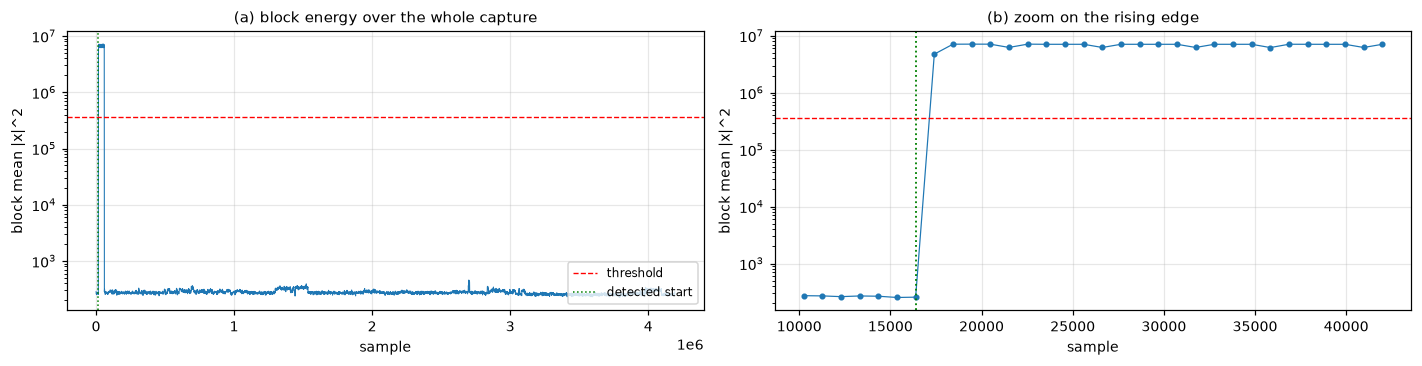

In [28]:
a, b = D.find_active(x)
off = max(0, a)

blk = 1024
nb = len(x) // blk
eb = (np.abs(x[:nb * blk]) ** 2).reshape(nb, blk).mean(axis=1)

print("检测到活跃区间 [%d, %d)，长 %d 点" % (a, b, b - a))
print("作为窗口起点 off = %d（已含 1 块前移余量）" % off)
print("真实突发应在 %d 附近（03 的 lead=%d 是发送缓冲内的偏移，两者不必相等）"
      % (off, LEAD))
print()
base = np.percentile(eb, 5)
print("静默基线能量 %.1f LSB²（≈ rms %.1f LSB）" % (base, np.sqrt(base)))
print("峰值块能量   %.1f LSB²  → 阈值 %.1f"
      % (eb.max(), base + 0.05 * (eb.max() - base)))

fig, ax = plt.subplots(1, 2, figsize=(13.0, 3.4))
show = min(nb, 4200)
ax[0].semilogy(np.arange(show) * blk, eb[:show] + 1e-6, lw=0.7)
ax[0].axhline(base + 0.05 * (eb.max() - base), color="r", ls="--", lw=0.9,
              label="threshold")
ax[0].axvline(a, color="g", ls=":", lw=1.0, label="detected start")
ax[0].set_xlabel("sample"); ax[0].set_ylabel("block mean |x|^2")
ax[0].set_title("(a) block energy over the whole capture")
ax[0].legend(loc="lower right")

m = slice(max(0, a // blk - 6), min(nb, a // blk + 26))
ax[1].semilogy((np.arange(nb)[m]) * blk, eb[m] + 1e-6, "o-", ms=3, lw=0.8)
ax[1].axhline(base + 0.05 * (eb.max() - base), color="r", ls="--", lw=0.9)
ax[1].axvline(a, color="g", ls=":", lw=1.2)
ax[1].set_xlabel("sample"); ax[1].set_ylabel("block mean |x|^2")
ax[1].set_title("(b) zoom on the rising edge")
plt.tight_layout(); plt.show()

## ② 去直流

RFSoC 的 ADC/DAC 都有直流失调，不去掉会在星座上加一个固定偏移，直接把 EVM 顶起来
（而且这个偏移会污染前导相位斜率，看起来像"有频偏"）。

估计方法：找**整包能量最低的块**（突发只占整包 1~2%，这些块就是纯静默 + 直流），
取其 I/Q 中位数。不能用"最低 20% 分位"，那样在缓冲较短、突发占多数时会把信号块选进来，
估出过 5000 LSB 的假直流，把相位斜率带偏成 −13 kHz。

窗口 45696 点（发送突发 43648 点 + 2048 余量）
直流估计 +0.0 +0.0j LSB（板上实测 < 1 LSB，可忽略；若上百 LSB 则必须减）
去直流前 |x| 均值 2381.4，去直流后 rms 2539.2 LSB
静默块噪声 rms 15.7 LSB  →  段内 SNR ≈ 44.2 dB
段内波峰因数 1.63（干净 QPSK ≈ 1.6；≥ 3.4 说明双边带污染）


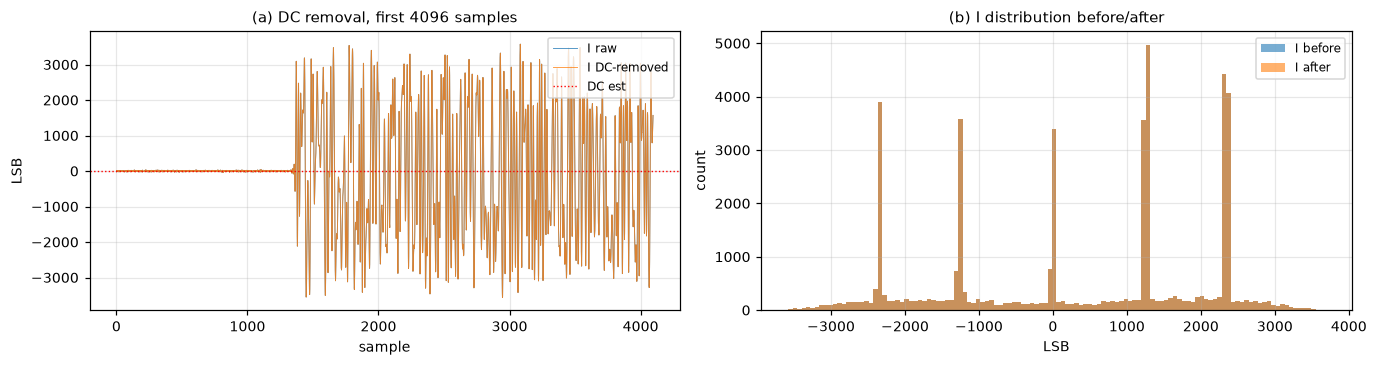

In [29]:
seg = x[off:min(len(x), off + BB_LEN + 2 * 1024)]
dc = D.estimate_dc(x)
seg_c = seg - dc

rms = float(np.sqrt(np.mean(np.abs(seg_c) ** 2)))

noise_rms = float(np.sqrt(base))
crest_seg = float(np.max(np.abs(seg_c))) / rms

print("窗口 %d 点（发送突发 %d 点 + 2048 余量）" % (len(seg), BB_LEN))
print("直流估计 %+.1f %+.1fj LSB（板上实测 < 1 LSB，可忽略；若上百 LSB 则必须减）"
      % (dc.real, dc.imag))
print("去直流前 |x| 均值 %.1f，去直流后 rms %.1f LSB" % (np.mean(np.abs(seg)), rms))
print("静默块噪声 rms %.1f LSB  →  段内 SNR ≈ %.1f dB"
      % (noise_rms, 20 * np.log10(rms / noise_rms)))
print("段内波峰因数 %.2f（干净 QPSK ≈ 1.6；≥ 3.4 说明双边带污染）" % crest_seg)

fig, ax = plt.subplots(1, 2, figsize=(12.6, 3.4))
q = min(len(seg), 4096)
ax[0].plot(seg.real[:q], lw=0.6, alpha=0.8, label="I raw")
ax[0].plot(seg_c.real[:q], lw=0.6, alpha=0.8, label="I DC-removed")
ax[0].axhline(dc.real, color="r", ls=":", lw=0.9, label="DC est")
ax[0].set_title("(a) DC removal, first %d samples" % q)
ax[0].set_xlabel("sample"); ax[0].set_ylabel("LSB"); ax[0].legend(loc="upper right")

ax[1].hist(seg.real, bins=120, alpha=0.6, label="I before")
ax[1].hist(seg_c.real, bins=120, alpha=0.6, label="I after")
ax[1].set_title("(b) I distribution before/after")
ax[1].set_xlabel("LSB"); ax[1].set_ylabel("count"); ax[1].legend(loc="upper right")
plt.tight_layout(); plt.show()

## ③ 匹配滤波 + 频谱方向自判

先过 RRC 匹配滤波（收发各一次，总响应升余弦，无 ISI）。

**方向自判**：本板 DAC 上混频与 ADC 下混频用的是同一符号约定，环回基带等于发送基带的**共轭**
（单音探针实测：+2/+4/+8/+12/+16 MHz 全部精确映射成 −f，无频偏、无比例误差）。
共轭的 QPSK 星座本身看起来一样（四个点对称），所以不会报错，但比特顺序会整体反转。
判据很简单：分别与 `前导` 和 `conj(前导)` 做相关，哪个峰高就是哪个方向。

与 前导   相关峰 4.279e+05
与 conj(前导) 相关峰 1.287e+06
判定 : 收到共轭信号，已翻转   (比值 3.01)

匹配滤波后长度 45696，理论群延迟 (len(h)-1)/2 = 48 点


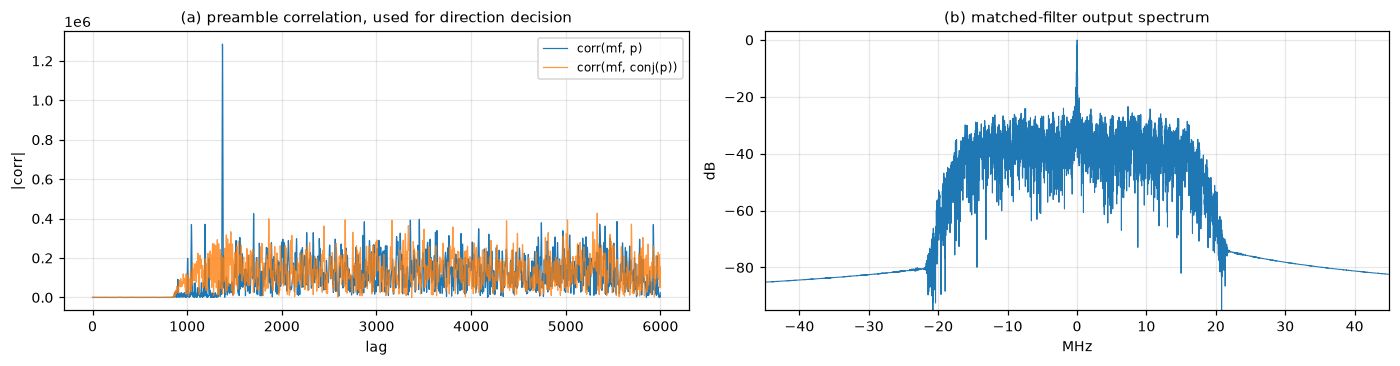

In [30]:
mf_raw = np.convolve(seg_c, h, mode="full")[:len(seg_c)]
pre = D.zc()
p = D.pulse_shape(pre, h, SPS)

c_n = float(np.abs(D.xcorr_valid(mf_raw, p)).max())
c_c = float(np.abs(D.xcorr_valid(mf_raw, np.conj(p))).max())
conjugated = c_c > c_n
mf = np.conj(mf_raw) if conjugated else mf_raw

print("与 前导   相关峰 %.4g" % c_n)
print("与 conj(前导) 相关峰 %.4g" % c_c)
print("判定 : %s   (比值 %.2f)" % ("收到共轭信号，已翻转" if conjugated else "同相，无需处理",
                                (c_c / c_n) if c_n else float("inf")))
print()
print("匹配滤波后长度 %d，理论群延迟 (len(h)-1)/2 = %d 点"
      % (len(mf), (len(h) - 1) // 2))

fig, ax = plt.subplots(1, 2, figsize=(12.8, 3.4))
cw = 6000
ax[0].plot(np.abs(D.xcorr_valid(mf, p))[:cw], lw=0.8, label="corr(mf, p)")
ax[0].plot(np.abs(D.xcorr_valid(mf, np.conj(p)))[:cw], lw=0.8,
           alpha=0.8, label="corr(mf, conj(p))")
ax[0].set_title("(a) preamble correlation, used for direction decision")
ax[0].set_xlabel("lag"); ax[0].set_ylabel("|corr|"); ax[0].legend(loc="upper right")

X = np.fft.fftshift(np.fft.fft(mf[:1 << 15], 1 << 15))
fq = (np.arange(len(X)) - len(X) // 2) / len(X) * FS_WORD / 1e6
ax[1].plot(fq, 20 * np.log10(np.abs(X) / np.abs(X).max() + 1e-12), lw=0.7)
ax[1].set_title("(b) matched-filter output spectrum")
ax[1].set_xlabel("MHz"); ax[1].set_ylabel("dB")
ax[1].set_xlim(-45, 45); ax[1].set_ylim(-95, 3)
plt.tight_layout(); plt.show()

## ④ 粗定时 + 粗频偏

`acquire()` 在**整段**上做粗捕获：以自适应步长扫频（步长 = 0.25 / 前导时长），
每个频点算一次前导相关，取相关最大的频点作为粗频偏，再在该频点上取**最早**的强相关峰。

取"最早"而不是"最大"：突发里每帧前导等幅，`argmax` 会随机锁到中间某一帧，
后面按 `center + i×帧长` 递推就会错位。

板上的粗频偏一般接近 0（同板共用时钟），扫频主要是为了兜住 PLL 的初值。

In [31]:
k_peak, f_c, step, snr_c = D.acquire(mf, p, SPS, D.N_PRE, FS_WORD, cfo_max=60e3)
h_delay = (len(h) - 1) // 2
center0 = k_peak + h_delay

print("扫频步长 %.1f Hz（= 0.25 / 前导时长）" % step)
print("粗频偏 f_coarse = %+.1f Hz" % f_c)
print("前导相关峰滞后 k_peak = %d" % k_peak)
print("→ 第 0 帧符号起点 center0 = k_peak + h_delay = %d" % center0)
seg_p = mf[k_peak:k_peak + len(p)]
rho = float(np.abs(np.vdot(seg_p, p))
            / max(np.linalg.norm(seg_p) * np.linalg.norm(p), 1e-12))
print("前导归一化相关系数 rho = %.4f  (1.0 = 完全相干，< 0.8 说明锁到了杂散峰)" % rho)
print()
print("帧间距应为 %d 点；按此递推，末帧 center = %d，缓冲 %d 点 %s"
      % (SPF_SMP, center0 + (N_FRAMES - 1) * SPF_SMP,
         len(mf), "✓ 在范围内" if center0 + (N_FRAMES - 1) * SPF_SMP < len(mf) else "⚠ 越界"))

扫频步长 125000.0 Hz（= 0.25 / 前导时长）
粗频偏 f_coarse = -0.0 Hz
前导相关峰滞后 k_peak = 1373
→ 第 0 帧符号起点 center0 = k_peak + h_delay = 1421
前导归一化相关系数 rho = 0.9412  (1.0 = 完全相干，< 0.8 说明锁到了杂散峰)

帧间距应为 4736 点；按此递推，末帧 center = 39309，缓冲 45696 点 ✓ 在范围内


## ⑤~⑧ 逐帧精同步与解调

`frame_sync()` 内部一次完成四步，这里直接对 9 帧各调一次。每帧返回：

- `got`　解出的比特
- `sym`　判决前的归一化符号（画星座/EVM 用）
- `inf`　`t0` 分数定时、`amp` 前导幅度、`ph0`/`slope` 前导相位拟合、`cfo_hz` 残余频偏

**为什么要精同步**：粗捕获只有 1 个样点的定时精度，而 1 个样点 = 1/8 符号的定时误差，
在 RRC α=0.35 下会带来约 20% 的 EVM —— 噪声还没进来就已经输了。所以必须做分数定时（三次插值）。

**为什么频偏搜索带宽要限制**：ZC 前导的相位是二次型，把它平移 1 个符号，等效于
`−ZC_ROOT/N_PRE × Rs` 的频偏（本例 −48.8 kHz）。不限带宽的话，"晚一个符号"和"一个巨大频偏"
在数学上完全等价，解出来就是星座正常但比特整体错位。

In [32]:
res, infos, syms, gots = [], [], [], []
for i, (tag, bits) in enumerate(zip(tags, truth)):
    n_data = len(bits) // 2
    center = center0 + i * SPF_SMP
    got, sym, inf = D.frame_sync(mf, h, pre, SPS, D.N_PRE, n_data, FS_WORD,
                                 center=center, span=3 * SPS, cfo_max=60e3)
    err = int(np.sum(got != bits))
    evm = D.evm_percent(sym, D.mod_qpsk(bits))
    gots.append(got); syms.append(sym); infos.append(inf)
    res.append(dict(tag=tag, n=len(bits), err=err, ber=err / len(bits), evm=evm,
                    t0=inf["t0"], cfo=inf["cfo_hz"], amp=inf["amp"],
                    gain=inf["gain"], fc=inf["cfo_coarse"]))

print("%-9s %7s %6s %8s %8s %11s %10s %8s" %
      ("图样", "比特", "错位", "BER", "EVM%", "t0", "残余频偏Hz", "前导增益"))
print("-" * 78)
for r in res:
    print("%-9s %7d %6d %8.2e %8.3f %11.2f %10.1f %8.3f"
          % (r["tag"], r["n"], r["err"], r["ber"], r["evm"], r["t0"],
             r["cfo"], r["gain"]))

tot = sum(r["n"] for r in res)
bad = sum(r["err"] for r in res)
t0s = np.array([r["t0"] for r in res])
d = np.diff(t0s)
print()
print("合计 %d 比特，错 %d 位 → BER = %.3e" % (tot, bad, bad / tot))
print("t0 间距：均值 %.2f 点（应为 %d），抖动 ±%.2f 点"
      % (d.mean(), SPF_SMP, 0.5 * (d.max() - d.min())))
print("残余频偏：中位数 %+.1f Hz，范围 %+.1f ~ %+.1f Hz"
      % (np.median([r["cfo"] for r in res]),
         min(r["cfo"] for r in res), max(r["cfo"] for r in res)))

图样             比特     错位      BER     EVM%          t0     残余频偏Hz     前导增益
------------------------------------------------------------------------------
rand         1024      0 0.00e+00    1.940     1421.22      -98.7 7560.952
zeros        1024      0 0.00e+00    0.590     6157.22      -72.9 7558.150
ones         1024      0 0.00e+00    0.603    10893.28     -144.6 7559.492
alt          1024      0 0.00e+00    0.576    15629.24        8.8 7557.466
aa           1024      0 0.00e+00    0.528    20365.26      -39.6 7552.729
55           1024      0 0.00e+00    0.548    25101.24      -49.3 7553.061
cnt          1024      0 0.00e+00    1.786    29837.22       84.7 7554.804
prbs9        1024      0 0.00e+00    1.937    34573.22      175.5 7554.330
onehot       1024      0 0.00e+00    0.587    39309.24      -78.9 7554.905

合计 9216 比特，错 0 位 → BER = 0.000e+00
t0 间距：均值 4736.00 点（应为 4736），抖动 ±0.05 点
残余频偏：中位数 -49.3 Hz，范围 -144.6 ~ +175.5 Hz


## ⑥ 前导相位拟合：看清"为什么要锁相环"

前导 64 个符号的相位对 `s·conj(pre)` 取角度后应是一条直线，斜率 = 残余频偏，截距 = 初相。

问题在于：**64 个符号估出的斜率本身带有估计噪声，外推到 512~2048 个数据符号时会累积成可观的相位漂移。**
频偏越大、帧越长，漂移越严重：在对算法做仿真验证时，残余频偏 3 kHz、帧长 1024 符号的配置下，
开环外推累积到 1~2 rad，星座从 ±45° 转到别的角度，BER 直接 50%。

板上的残余频偏通常很小（同板共用时钟），所以本次开环与闭环差别只有不到 1 个百分点。
但"小"是运气，不是保证 —— 换一次抓取、换一块板、换一个 NCO 配置都可能变大，
所以接收机里 PLL 必须常开。下面这个单元会**同时算两种做法**并给出各自的 EVM，差别一目了然。

第 0 帧（rand）
前导幅度 amp = 7562.2 LSB
相位斜率 slope = -0.00002 rad/symbol → 残余频偏 -98.7 Hz
初相 ph0 = +0.2875 rad
前导 64 符号内的相位总漂移 -0.0012 rad（斜率×63）
若外推到 512 个数据符号：漂移 -0.010 rad = -0.57 度
  → 本次残余频偏低、漂移很小，开环与闭环差别不大；但换一次抓取或换频偏配置就可能变大，PLL 是必要的保险

前导相位残差（去线性趋势后）标准差 0.0185 rad，最大 |残差| 0.0337 rad


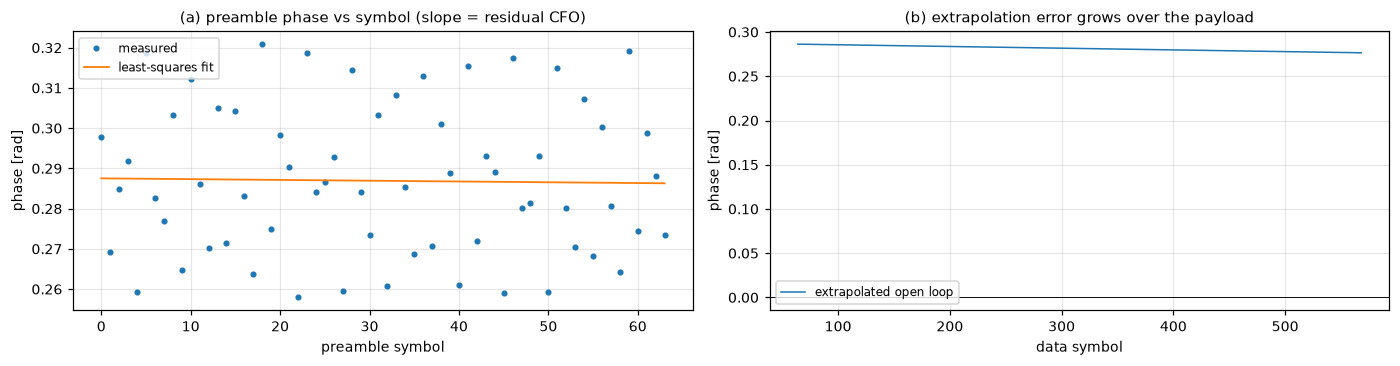

In [33]:
i = 0
inf = infos[i]
m_idx = np.arange(D.N_PRE)
n_data = len(truth[i]) // 2
k_all = D.N_PRE + np.arange(n_data)

y_pre = D.interp_cubic(mf, inf["t0"] + m_idx * SPS)
y_dat = D.interp_cubic(mf, inf["t0"] + k_all * SPS)
gc = y_pre * np.conj(pre)
ph = np.unwrap(np.angle(gc))

print("第 0 帧（%s）" % tags[i])
print("前导幅度 amp = %.1f LSB" % inf["amp"])
print("相位斜率 slope = %+.5f rad/symbol → 残余频偏 %+.1f Hz"
      % (inf["slope"], inf["slope"] / (2 * np.pi) * FS_WORD / SPS))
print("初相 ph0 = %+.4f rad" % inf["ph0"])
drift = inf["slope"] * n_data
print("前导 64 符号内的相位总漂移 %.4f rad（斜率×63）" % (inf["slope"] * 63))
print("若外推到 %d 个数据符号：漂移 %.3f rad = %.2f 度"
      % (n_data, drift, np.degrees(drift)))
print("  →", ("漂移超过 0.3 rad，开环补偿会明显退化，必须靠 PLL 拉回"
              if abs(drift) > 0.3 else
              "本次残余频偏低、漂移很小，开环与闭环差别不大；"
              "但换一次抓取或换频偏配置就可能变大，PLL 是必要的保险"))
print()
print("前导相位残差（去线性趋势后）标准差 %.4f rad，最大 |残差| %.4f rad"
      % (np.std(ph - np.polyval(np.polyfit(m_idx, ph, 1), m_idx)),
         np.max(np.abs(ph - np.polyval(np.polyfit(m_idx, ph, 1), m_idx)))))

fig, ax = plt.subplots(1, 2, figsize=(12.8, 3.4))
ax[0].plot(m_idx, ph, "o", ms=3, label="measured")
ax[0].plot(m_idx, np.polyval(np.polyfit(m_idx, ph, 1), m_idx), "-", lw=1.2,
           label="least-squares fit")
ax[0].set_title("(a) preamble phase vs symbol (slope = residual CFO)")
ax[0].set_xlabel("preamble symbol"); ax[0].set_ylabel("phase [rad]")
ax[0].legend(loc="upper left")

k_show = np.arange(0, n_data, 8)
ax[1].plot(k_all[k_show], inf["ph0"] + inf["slope"] * k_all[k_show], lw=1.0,
           label="extrapolated open loop")
ax[1].axhline(0, color="k", lw=0.6)
ax[1].set_title("(b) extrapolation error grows over the payload")
ax[1].set_xlabel("data symbol"); ax[1].set_ylabel("phase [rad]")
ax[1].legend(loc="lower left")
plt.tight_layout(); plt.show()

## ⑦ 锁相环：开环 vs 闭环

用与前导同一套参数复现 `frame_sync` 第 ③~④ 步，对比两种做法：

- **开环**：`s = y / (amp · exp(j(ph0 + slope·k)))`，只用前导拟合出的直线
- **闭环**：同样作为初值送进二阶判决引导 PLL（`kp=0.05, ki=1e-4`），逐符号修正

PLL 的判决误差每步最多修正 `kp × e`（`e ≤ π/4`）≈ 2.2°，所以**单步修正有界、不会滑周**；
而之前试过的"分块四次方估计"会在残余相位超过 ±45° 时逐块跳支，`unwrap` 之后一错到底。

第 0 帧（rand，512 个数据符号）
  开环（仅前导外推）: EVM   2.09 %   错位 0 bit
  闭环（二阶 PLL）  : EVM   1.94 %   错位 0 bit

可视化版 PLL 与 qpsk_dsp.pll_track 输出一致: True
环路频偏 -101.7 Hz → -50.9 Hz（变化 50.8 Hz，环路已锁定）
累计相位修正 -0.000 rad


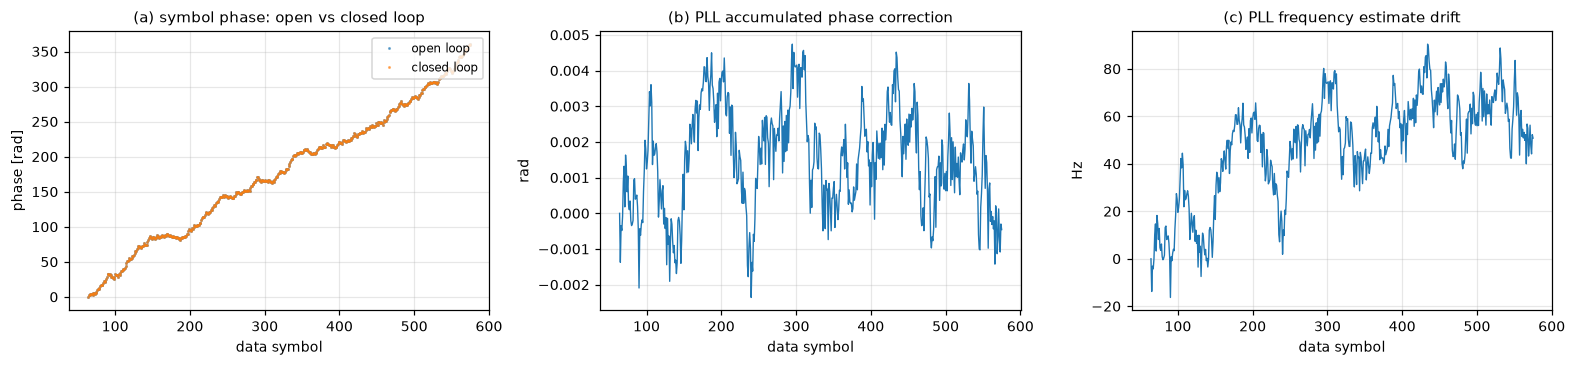

In [34]:
def pll_track_hist(y, f0=0.0, ph0=0.0, kp=0.05, ki=1e-4):
    # 与 D.pll_track 完全相同的算法，额外记录相位/频率历史，仅供作图
    n = len(y)
    out = np.empty(n, dtype=complex)
    hp = np.empty(n); hf = np.empty(n)
    ph = ph0 - f0
    f = f0
    for k in range(n):
        ph += f
        zc_ = y[k] * np.exp(-1j * ph)
        d = complex(1.0 if zc_.real >= 0 else -1.0,
                    1.0 if zc_.imag >= 0 else -1.0) / np.sqrt(2)
        e = np.angle(zc_ * np.conj(d))
        ph += kp * e
        f += ki * e
        out[k] = zc_ * np.exp(-1j * kp * e)
        hp[k] = ph; hf[k] = f
    return out, hp, hf


s_open = y_dat / (inf["amp"] * np.exp(1j * (inf["ph0"] + inf["slope"] * k_all)))
s_cl, ph_h, f_h = pll_track_hist(y_dat / inf["amp"], f0=inf["slope"],
                                 ph0=inf["ph0"] + inf["slope"] * D.N_PRE)

ref0 = D.mod_qpsk(truth[i])
evm_open = D.evm_percent(s_open, ref0)
evm_cl = D.evm_percent(s_cl, ref0)

# 一致性检查：可视化版本必须与模块版本逐点相同
same = np.allclose(s_cl, D.pll_track(y_dat / inf["amp"], f0=inf["slope"],
                                     ph0=inf["ph0"] + inf["slope"] * D.N_PRE))

print("第 0 帧（%s，%d 个数据符号）" % (tags[i], n_data))
print("  开环（仅前导外推）: EVM %6.2f %%   错位 %d bit" %
      (evm_open, int(np.sum(D.demod_qpsk(s_open) != truth[i]))))
print("  闭环（二阶 PLL）  : EVM %6.2f %%   错位 %d bit" %
      (evm_cl, int(np.sum(D.demod_qpsk(s_cl) != truth[i]))))
print()
print("可视化版 PLL 与 qpsk_dsp.pll_track 输出一致:", same)
print("环路频偏 %+.1f Hz → %+.1f Hz（变化 %.1f Hz，环路已锁定）"
      % (f_h[0] / (2 * np.pi) * FS_WORD / SPS, f_h[-1] / (2 * np.pi) * FS_WORD / SPS,
         (f_h[-1] - f_h[0]) / (2 * np.pi) * FS_WORD / SPS))
print("累计相位修正 %.3f rad" % (ph_h[-1] - ph_h[0]))

fig, ax = plt.subplots(1, 3, figsize=(14.4, 3.4))

ax[0].plot(k_all, np.unwrap(np.angle(s_open)), ".", ms=2, alpha=0.55, label="open loop")
ax[0].plot(k_all, np.unwrap(np.angle(s_cl)), ".", ms=2, alpha=0.55, label="closed loop")
ax[0].set_title("(a) symbol phase: open vs closed loop")
ax[0].set_xlabel("data symbol"); ax[0].set_ylabel("phase [rad]")
ax[0].legend(loc="upper right")

ax[1].plot(k_all, (ph_h - ph_h[0]), lw=0.9)
ax[1].set_title("(b) PLL accumulated phase correction")
ax[1].set_xlabel("data symbol"); ax[1].set_ylabel("rad")

ax[2].plot(k_all, (f_h - f_h[0]) / (2 * np.pi) * FS_WORD / SPS, lw=0.9)
ax[2].set_title("(c) PLL frequency estimate drift")
ax[2].set_xlabel("data symbol"); ax[2].set_ylabel("Hz")
plt.tight_layout(); plt.show()

## ⑧ 星座对比

左边是开环、右边是闭环，参考点用灰叉标出。

- 残余频偏较大时：开环星座会沿圆弧"飘走"，闭环被拉回四个理想点，EVM 从几十个百分点降到百分之几
- 残余频偏很小时（本次）：两者都聚在理想点附近，差别只在零点几个百分点

所以这两张图要结合上面的"外推漂移"数值一起看：**漂移大则闭环收益大**，
漂移小则说明这次的频偏条件比较宽松，不代表可以省掉 PLL。

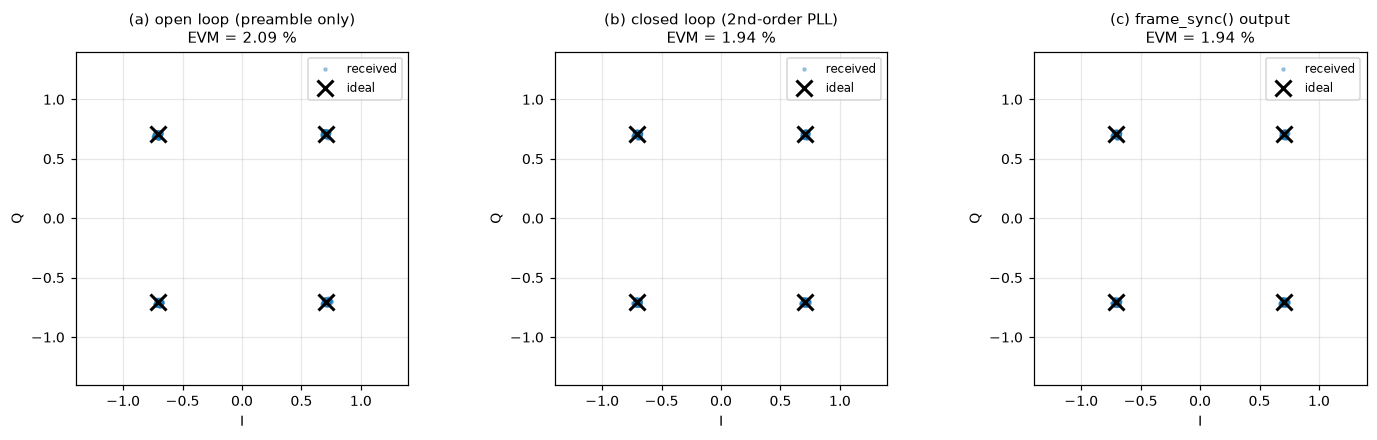

In [35]:
fig, ax = plt.subplots(1, 3, figsize=(13.2, 4.0))
pts = np.array([1 + 1j, 1 - 1j, -1 + 1j, -1 - 1j]) / np.sqrt(2)


def draw(axi, s, title, evm):
    axi.plot(s.real, s.imag, ".", ms=4, alpha=0.35, label="received")
    axi.plot(pts.real, pts.imag, "x", ms=11, mew=2, color="k", label="ideal")
    axi.set_title("%s\nEVM = %.2f %%" % (title, evm))
    axi.set_xlabel("I"); axi.set_ylabel("Q"); axi.set_aspect("equal")
    axi.set_xlim(-1.4, 1.4); axi.set_ylim(-1.4, 1.4)
    axi.legend(loc="upper right")


evm_frame = D.evm_percent(syms[i], ref0)

draw(ax[0], s_open, "(a) open loop (preamble only)", evm_open)
draw(ax[1], s_cl, "(b) closed loop (2nd-order PLL)", evm_cl)
draw(ax[2], syms[i], "(c) frame_sync() output", evm_frame)
plt.tight_layout(); plt.show()

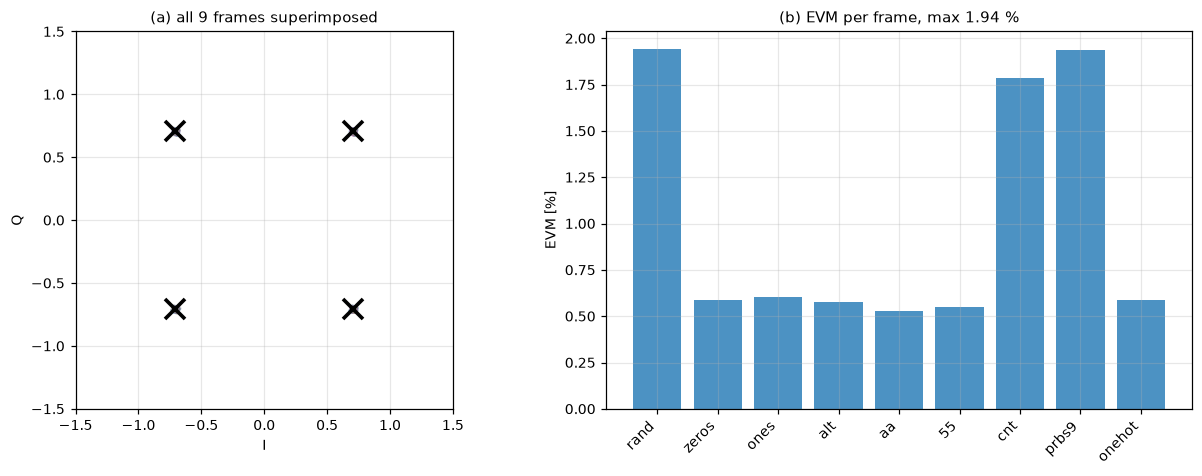

EVM 中位数 0.59 %，最大 1.94 %
对应 SNR ≈ 44.6 dB（EVM% = 100/sqrt(SNR) 的反解）


In [36]:
# 9 帧全部叠在一起看
fig, ax = plt.subplots(1, 2, figsize=(11.6, 4.4))
for i2 in range(N_FRAMES):
    ax[0].plot(syms[i2].real, syms[i2].imag, ".", ms=1.6, alpha=0.20)
ax[0].plot(pts.real, pts.imag, "x", ms=13, mew=2.4, color="k")
ax[0].set_title("(a) all %d frames superimposed" % N_FRAMES)
ax[0].set_xlabel("I"); ax[0].set_ylabel("Q"); ax[0].set_aspect("equal")
ax[0].set_xlim(-1.5, 1.5); ax[0].set_ylim(-1.5, 1.5)

evs = [r["evm"] for r in res]
ax[1].bar(range(N_FRAMES), evs, color="tab:blue", alpha=0.8)
ax[1].set_xticks(range(N_FRAMES))
ax[1].set_xticklabels(tags, rotation=45, ha="right")
ax[1].set_ylabel("EVM [%]")
ax[1].set_title("(b) EVM per frame, max %.2f %%" % max(evs))
plt.tight_layout(); plt.show()

print("EVM 中位数 %.2f %%，最大 %.2f %%"
      % (np.median(evs), max(evs)))
print("对应 SNR ≈ %.1f dB（EVM%% = 100/sqrt(SNR) 的反解）"
      % (20 * np.log10(100.0 / np.median(evs))))

## 存盘，交给 03校验

存判决结果、判决前符号、每帧同步参数，以及匹配滤波后的整段 `mf`（05 画眼图要用）。

In [37]:
pay = dict(
    mf=np.asarray(mf, dtype=np.complex64),
    off=np.int64(off), dc=np.complex128(dc),
    conjugated=np.bool_(conjugated),
    k_peak=np.int64(k_peak), f_coarse=np.float64(f_c), center0=np.int64(center0),
    sps=np.int64(SPS), n_frames=np.int64(N_FRAMES),
    spf_smp=np.int64(SPF_SMP), fs_word=np.float64(FS_WORD),
    n_pre=np.int64(D.N_PRE), n_bits=np.int64(N_BITS),
)
for i2, (tag, bits) in enumerate(zip(tags, truth)):
    pay["truth_%d" % i2] = np.asarray(bits, dtype=np.uint8)
    pay["got_%d" % i2] = np.asarray(gots[i2], dtype=np.uint8)
    pay["sym_%d" % i2] = np.asarray(syms[i2], dtype=np.complex64)
    pay["t0_%d" % i2] = np.float64(infos[i2]["t0"])
    pay["amp_%d" % i2] = np.float64(infos[i2]["amp"])
    pay["cfo_%d" % i2] = np.float64(infos[i2]["cfo_hz"])
    pay["ph0_%d" % i2] = np.float64(infos[i2]["ph0"])
    pay["slope_%d" % i2] = np.float64(infos[i2]["slope"])
pay["tags"] = np.array(tags, dtype="U16")

np.savez_compressed(NPZ_RX, **pay)
print("已保存 %s (%.2f MB)" % (NPZ_RX, os.path.getsize(NPZ_RX) / 1e6))
print()
print("下一步：打开 05_qpsk_verify.ipynb，它会独立读 03 的真值和本文件的判决结果做逐比特比对")

已保存 /home/xilinx/qpsk/qpsk_04_demod.npz (0.35 MB)

下一步：打开 05_qpsk_verify.ipynb，它会独立读 03 的真值和本文件的判决结果做逐比特比对


---
## 附：接收机每一步的判据一览

| 步骤 | 函数 | 正常范围 | 越界说明 |
|---|---|---|---|
| 突发定位 | `find_active` | 起点偏差 < 1024 点 | 漏掉首块 → 错位一帧 |
| 去直流 | `estimate_dc` | \|DC\| < 0.05×rms | 偏大会抬高 EVM + 伪造频偏 |
| 方向自判 | 相关比 | 两路差 > 1.5 倍 | 接近 1 说明是双边带污染状态 |
| 粗定时 | `acquire` | 相关信噪比 > 12 dB | 低于 8 dB 考虑加长前导 |
| 分数定时 | `frame_sync` | \|t0 − 整数中心\| ≤ 1 | 到边界说明粗捕获选错帧 |
| 前导拟合 | `polyfit` | 残差 < 0.15 rad | 偏大说明多径/相位噪声 |
| PLL | `pll_track` | 频偏漂移 < 50 Hz | 偏大说明环路带宽不匹配 |
| 判决 | `demod_qpsk` | 无一错位 | — |